In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hw5.ipynb")

# CPSC 330 - Applied Machine Learning 

## Homework 5: Credit default classification 
### Associated lectures: All material till Chapter 13 

## Table of contents
0. [Submission instructions](#si)
1. [Understanding the problem](#1)
2. [Data splitting](#2)
3. [EDA](#3)
4. (Challenging) [Feature engineering](#4)
5. [Preprocessing and transformations](#5) 
6. [Baseline model](#6)
7. [Linear models](#7)
8. [Different models](#8)
9. (Challenging) [Feature selection](#9)
10. [Hyperparameter optimization](#10)
11. [Interpretation and feature importances](#11) 
12. [Results on the test set](#12)
13. [Summary of the results](#13)
14. (Challenging) [Your takeaway from the course](#15)

<div class="alert alert-info">

## Instructions
rubric={points}

You will earn points for following these instructions and successfully submitting your work in PrairieLearn.

### Group work instructions

**You may work with a partner on this homework and submit your assignment as a group.** Below are some instructions on working as a group.

- The maximum group size is 2.
- Use group work as an opportunity to collaborate and learn new things from each other.
- Be respectful to each other and make sure you understand all the concepts in the assignment well.
- It is your responsibility to make sure your PrairieLearn group is set up correctly and that the assignment is submitted before the deadline.

### General submission instructions

- Please read the [Use of Generative AI policy](https://ubc-cs.github.io/cpsc330-2026W1/syllabus/#use-of-generative-ai-genai) before starting the homework assignment.
- **Run all cells before submitting:** Go to `Kernel -> Restart Kernel and Clear All Outputs`, then select `Run -> Run All Cells`. This ensures your notebook runs cleanly from start to finish without errors.
- **Save your work in JupyterLab:** Make sure `hw5.ipynb` is saved.
- **Choose one HW5 option:** HW5 has two dataset options in PrairieLearn. You are currently in the credit default classification option. Open and submit exactly one notebook, and do not submit both.
- **Check your saved submission in PrairieLearn:** Return to the PrairieLearn question page and click **Save only** to capture your notebook and review the preview. When you are ready to submit for grading, click **Save & Grade**.
- **Follow course submission guidelines:** Review the CPSC 330 homework instructions for detailed guidance on completing and submitting assignments.

</div>


Final test F1-score: 0.4722 - tuned random forest, default (1) as the positive class.

## Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap as shap
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

<!-- BEGIN QUESTION -->



In [3]:
...

Ellipsis

<!-- END QUESTION -->

## Introduction <a name="in"></a>

In this homework you will be working on an open-ended mini-project, where you will put all the different things you have learned so far together to solve an interesting problem.

A few notes and tips when you work on this mini-project: 

#### Tips
1. This mini-project is open-ended, and while working on it, there might be some situations where you'll have to use your own judgment and make your own decisions (as you would be doing when you work as a data scientist). Make sure you explain your decisions whenever necessary. 
2. **Do not include everything you ever tried in your submission** -- it's fine just to have your final code. That said, your code should be reproducible and well-documented. For example, if you chose your hyperparameters based on some hyperparameter optimization experiment, you should leave in the code for that experiment so that someone else could re-run it and obtain the same hyperparameters, rather than mysteriously just setting the hyperparameters to some (carefully chosen) values in your code. 
3. If you realize that you are repeating a lot of code try to organize it in functions. Clear presentation of your code, experiments, and results is the key to be successful in this lab. You may use code from lecture notes or previous lab solutions with appropriate attributions. 

#### Assessment
We plan to grade fairly and leniently. We don't have some secret target score that you need to achieve to get a good grade. **You'll be assessed on demonstration of mastery of course topics, clear presentation, and the quality of your analysis and results.** For example, if you just have a bunch of code and no text or figures, that's not good. If you do a bunch of sane things and get a lower accuracy than your friend, don't sweat it.


#### A final note
Finally, this style of this "project" question is different from other assignments. It'll be up to you to decide when you're "done" -- in fact, this is one of the hardest parts of real projects. But please don't spend WAY too much time on this... perhaps "a few hours" (15-20 hours???) is a good guideline for this project . Of course if you're having fun you're welcome to spend as much time as you want! But, if so, try not to do it out of perfectionism or getting the best possible grade. Do it because you're learning and enjoying it. Students from the past cohorts have found such kind of labs useful and fun and we hope you enjoy it as well. 

<br><br>

<!-- BEGIN QUESTION -->

<!-- BEGIN QUESTION -->

## 1. Pick your problem and explain the prediction problem
<hr>
rubric={points:3}

This version of Homework 5 uses the [Default of Credit Card Clients Dataset](https://www.kaggle.com/uciml/default-of-credit-card-clients-dataset). You will work on a classification problem where the goal is to predict whether a credit card client will default on their payment next month. In this dataset, there are 30,000 examples and 24 features, and the target column is labeled `default.payment.next.month`. The remaining columns can be used as features. You may take some ideas and compare your results with [the associated research paper](https://www.sciencedirect.com/science/article/pii/S0957417407006719), which is available through [the UBC library](https://www.library.ubc.ca/).

<div class="alert alert-info">
    
**Your tasks:**

1. Spend some time understanding the problem and what each feature means. Use the Kaggle documentation to guide you.
2. Download the dataset and load it into a pandas DataFrame.
3. Write a few sentences summarizing your initial thoughts about the problem and the dataset.
   
</div>


<div class="alert alert-warning">
    
Solution_1
    
</div>

_Points:_ 3

This dataset aims to predict whether a credit card client will default on their payment in the following month. This is a binary classification problem, where default.payment.next.month is the target: 1 means default and 0 means no default. It includes information such as age, gender, education, marital status, as well as financial information such as credit limits, payment history, and bill amounts. We think payment history and credit limits could be important predictors of default because they reflect a client's past payment behaviour and financial situation. 

In [4]:
df = pd.read_csv("UCI_Credit_Card.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 2. Data splitting <a name="2"></a>
<hr>
rubric={points:2}

**Your tasks:**

1. Split the data into train (70%) and test (30%) portions with `random_state=123`.

> If your computer cannot handle training on 70% training data, make the test split bigger.  

<div class="alert alert-warning">
    
Solution_2
    
</div>

_Points:_ 2

In [5]:
train_df, test_df = train_test_split(df, test_size=0.3, random_state=123)

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 3. EDA <a name="3"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Perform exploratory data analysis on the train set.
2. Include at least two summary statistics and two visualizations that you find useful, and accompany each one with a sentence explaining it.
3. Summarize your initial observations about the data. 
4. Pick appropriate metric/metrics for assessment. 

<div class="alert alert-warning">
    
Solution_3
    
</div>

_Points:_ 10

2. train_df.describe() provides summary statistics such as the mean, standard deviation, minimum, and maximum for numerical variables. It helps us understand the distribution of features such as age, credit limit, and bill amounts.
   
   train_df["default.payment.next.month"].value_counts() shows the proportion of clients who defaulted and did not default. It helps us identify whether the target classes are imbalanced.

   Distribution of Client Ages histogram shows the distribution of clients' ages, helping us identify the most common age ranges in the dataset.

   The boxplot compares the distribution of credit limits between clients who defaulted and those who did not. It helps us investigate whether credit limits are associated with default payments.

3. The dataset contains 21,000 clients in the training set, with approximately 77.7% not defaulting and 22.3% defaulting, indicating an imbalance in the target variable. The age distribution is right-skewed, with most clients between 25 and 40 years old. The boxplot shows that clients who did not default generally have higher median credit limits than those who defaulted. Overall, credit limits may be useful for predicting default payments.

4. I would use precision, recall, and F1-score to evaluate the classification model. Recall is important because we want to correctly identify clients who will default on their payments. Precision is also useful because we want to avoid incorrectly predicting that clients will default. F1-score provides a balance between precision and recall, making it useful since the dataset is imbalanced with majority of clients being non-default.

In [6]:
train_df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000,...,21000.000000,21000.000000,21000.000000,21000.000000,2.100000e+04,21000.000000,21000.000000,21000.000000,21000.000000,21000.000000
mean,14962.348238,167880.651429,1.600762,1.852143,1.554000,35.500810,-0.015429,-0.137095,-0.171619,-0.225238,...,43486.610905,40428.518333,38767.202667,5673.585143,5.895027e+03,5311.432286,4774.021381,4751.850095,5237.762190,0.223238
std,8650.734050,130202.682167,0.489753,0.792961,0.521675,9.212644,1.120465,1.194506,1.196123,1.168556,...,64843.303993,61187.200817,59587.689549,17033.241454,2.180143e+04,18377.997079,15434.136142,15228.193125,18116.846563,0.416427
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-50616.000000,-61372.000000,-339603.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7498.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2293.750000,1739.500000,1215.750000,1000.000000,8.200000e+02,390.000000,266.000000,234.000000,110.750000,0.000000
50%,14960.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19102.500000,18083.000000,16854.500000,2100.000000,2.007000e+03,1809.500000,1500.000000,1500.000000,1500.000000,0.000000
75%,22458.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54763.250000,50491.000000,49253.750000,5007.250000,5.000000e+03,4628.500000,4021.250000,4016.000000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.227082e+06,896040.000000,621000.000000,426529.000000,528666.000000,1.000000


In [7]:
train_df["default.payment.next.month"].value_counts(normalize=True)

default.payment.next.month
0    0.776762
1    0.223238
Name: proportion, dtype: float64

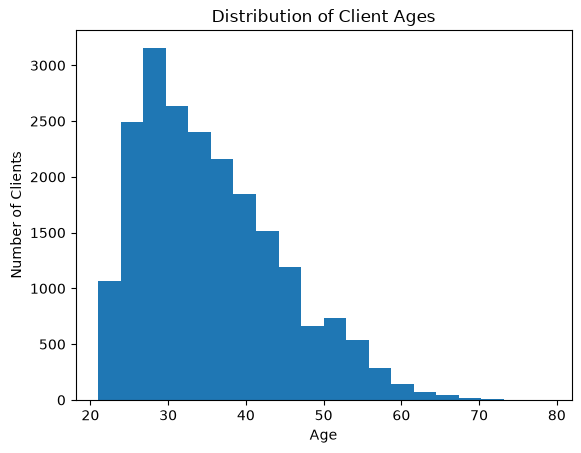

In [8]:
plt.hist(train_df["AGE"], bins=20)
plt.xlabel("Age")
plt.ylabel("Number of Clients")
plt.title("Distribution of Client Ages")
plt.show()

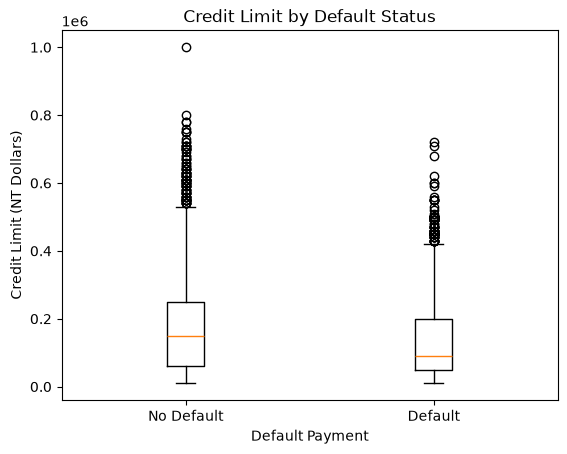

In [9]:
no_default = train_df.loc[train_df["default.payment.next.month"] == 0, "LIMIT_BAL"]
default = train_df.loc[train_df["default.payment.next.month"] == 1, "LIMIT_BAL"]

plt.boxplot([no_default, default], tick_labels=["No Default", "Default"])
plt.xlabel("Default Payment")
plt.ylabel("Credit Limit (NT Dollars)")
plt.title("Credit Limit by Default Status")
plt.show()

The median credit limit is NT$140,000, while the mean is approximately NT$167,881, suggesting a right-skewed distribution.

We will use F1-score as the primary metric, with default (1) as the positive class, and report precision and recall alongside it. Recall measures how many actual defaults we identify, while precision measures how many predicted defaults are correct. F1 balances these two measures. Accuracy alone could be misleading: always predicting non-default would achieve approximately 77.7% accuracy while identifying no defaults.

In [10]:
...

Ellipsis

In [11]:
...

Ellipsis

In [12]:
...

Ellipsis

In [13]:
...

Ellipsis

In [14]:
...

Ellipsis

In [15]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 4. Feature engineering <a name="4"></a>
<hr>
rubric={points:1}

**Your tasks:**

1. Carry out feature engineering. In other words, extract new features relevant for the problem and work with your new feature set in the following exercises. You may have to go back and forth between feature engineering and preprocessing. 

<div class="alert alert-warning">
    
Solution_4
    
</div>

_Points:_ 1

In [16]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]

train_df["AVG_BILL_AMT"] = train_df[bill_cols].mean(axis=1)
test_df["AVG_BILL_AMT"] = test_df[bill_cols].mean(axis=1)

We created a new feature called AVG_BILL_AMT to represent the average bill amount over six months.

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 5. Preprocessing and transformations <a name="5"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Identify any data cleaning that needs to be done and perform it.
2. Identify different feature types and the transformations you would apply on each feature type. 
3. Define a column transformer, if necessary.
4. You have likely noticed the `number_of_reviews` of reviews feature will be higly informative for the target `reviews_per_month`. To make this assignment more interesting **drop** the `number_of_reviews` feature.

<div class="alert alert-warning">
    
Solution_5
    
</div>

_Points:_ 10

For data cleaning, we grouped EDUCATION values 0, 5, and 6 into category 4 (“Others”) and the unknown MARRIAGE value 0 into category 3 (“Others”) as cleaning choices. We treated repayment status columns (PAY_*) as categorical to avoid assuming equal numerical effects between status codes. We excluded ID because it is a client identifier. Numerical features are median-imputed and standardized using StandardScaler, while categorical features are imputed with the most frequent value and one-hot encoded using OneHotEncoder. We defined a ColumnTransformer to apply these transformations.

In [17]:
for data in [train_df, test_df]:
    data["EDUCATION"] = data["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    data["MARRIAGE"] = data["MARRIAGE"].replace({0: 3})

In [18]:
numeric_features = ["LIMIT_BAL", "AGE", "BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "BILL_AMT4", "BILL_AMT5", "BILL_AMT6", "PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6", "AVG_BILL_AMT"]
categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

numeric_transformer = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler())

categorical_transformer = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)])

In [19]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(train_df[col].value_counts())

SEX
2    12616
1     8384
Name: count, dtype: int64
EDUCATION
2    9815
1    7433
3    3416
4     336
Name: count, dtype: int64
MARRIAGE
2    11210
1     9527
3      263
Name: count, dtype: int64


In [20]:
...

Ellipsis

In [21]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 6. Baseline model <a name="6"></a>
<hr>
rubric={points:2}

**Your tasks:**
1. Try `scikit-learn`'s baseline model and report results.

<div class="alert alert-warning">
    
Solution_6
    
</div>

_Points:_ 2

In [22]:
X_train = train_df.drop(columns=["default.payment.next.month"])
y_train = train_df["default.payment.next.month"]

dummy = DummyClassifier(strategy="most_frequent")

scores = cross_validate(
    dummy,
    X_train,
    y_train,
    cv=5,
    scoring=["accuracy", "precision", "recall", "f1"])

pd.DataFrame(scores).mean()

c:\Users\user\Downloads\New folder (2)\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\Downloads\New folder (2)\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\Downloads\New folder (2)\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

fit_time          0.002119
score_time        0.007491
test_accuracy     0.776762
test_precision    0.000000
test_recall       0.000000
test_f1           0.000000
dtype: float64

The baseline always predicts no default, the majority class. It achieves approximately 77.7% cross-validation accuracy, but recall and F1-score are 0 because it identifies no defaults. Precision is undefined because it never predicts default; scikit-learn reports it as 0 and raises a warning. These results show why accuracy alone is insufficient for evaluating this problem.

In [23]:
...

Ellipsis

In [24]:
...

Ellipsis

<!-- END QUESTION -->



<!-- BEGIN QUESTION -->

## 7. Linear models <a name="7"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Try a linear model as a first real attempt. 
2. Carry out hyperparameter tuning to explore different values for the complexity hyperparameter. 
3. Report cross-validation scores along with standard deviation. 
4. Summarize your results.

<div class="alert alert-warning">
    
Solution_7
    
</div>

_Points:_ 10

We used LogisticRegression as our first linear model and performed hyperparameter tuning using GridSearchCV with 5-fold cross-validation. We tested six different values of C and found that C = 10 gave the best performance, with a mean cross-validation F1-score of around 0.469 and standard deviation of 0.00993358. This is an improvement over the DummyClassifier baseline, which had an F1-score of 0.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=2000))

param_grid = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}


grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="f1",
    return_train_score=True)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=2000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scorin

In [26]:
print("CV standard deviation:", grid_search.cv_results_["std_test_score"])
print("Mean CV F1-scores:", grid_search.cv_results_["mean_test_score"])
print("Selected Setting", grid_search.best_params_)
print("Mean CV F1-score:", grid_search.best_score_)

CV standard deviation: [0.01612988 0.00501614 0.00867781 0.01020384 0.00998991 0.01053019]
Mean CV F1-scores: [0.26780182 0.42599576 0.46847277 0.46810669 0.4686607  0.46758658]
Selected Setting {'logisticregression__C': 10}
Mean CV F1-score: 0.46866070121077563


In [27]:
...

Ellipsis

In [28]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 8. Different models <a name="8"></a>
<hr>
rubric={points:12}

**Your tasks:**
1. Try at least 3 other models aside from a linear model. One of these models should be a tree-based ensemble model. 
2. Summarize your results in terms of overfitting/underfitting and fit and score times. Can you beat a linear model? 

<div class="alert alert-warning">
    
Solution_8
    
</div>

_Points:_ 12

We compared kNN, a decision tree, and a random forest. kNN showed overfitting, with training F1 of 0.565 versus CV F1 of 0.421. The random forest also showed overfitting, with training F1 of 0.579 versus CV F1 of 0.459. The depth-limited decision tree had a smaller gap (0.464 versus 0.432), but its lower scores suggest a more constrained model.

kNN had the shortest fit time (0.035 s) but the longest scoring time (1.393 s). The decision tree fit quickly (0.131 s) and scored fastest (0.010 s). The random forest took longest to fit (2.922 s), with a scoring time of 0.054 s. None exceeded logistic regression’s mean CV F1 of 0.469; the random forest came closest at 0.459.

In [29]:
models = {
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=123),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=123)}

for name, model in models.items():
    pipe = make_pipeline(preprocessor, model)
    scores = cross_validate(pipe, X_train, y_train, cv=5, scoring="f1", return_train_score=True)
    

    print(name)
    print("Train F1:", scores["train_score"].mean())
    print("CV F1:", scores["test_score"].mean())
    print("CV Std:", scores["test_score"].std())
    print("Fit Time:", scores["fit_time"].mean())
    print("Score Time:", scores["score_time"].mean())

kNN
Train F1: 0.56505175703146
CV F1: 0.4213009739846042
CV Std: 0.010830152044021067
Fit Time: 0.037311124801635745
Score Time: 1.3282206058502197
Decision Tree
Train F1: 0.4637933033821538
CV F1: 0.4323487847069926
CV Std: 0.012908614001399768
Fit Time: 0.12514181137084962
Score Time: 0.008794355392456054
Random Forest
Train F1: 0.5789302058359189
CV F1: 0.4594353281007155
CV Std: 0.002769427773375566
Fit Time: 2.7564993858337403
Score Time: 0.047965621948242186


In [30]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 9. Feature selection <a name="9"></a>
<hr>
rubric={points:2}

**Your tasks:**

Make some attempts to select relevant features. You may try `RFECV` or forward selection for this. Do the results improve with feature selection? Summarize your results. If you see improvements in the results, keep feature selection in your pipeline. If not, you may abandon it in the next exercises. 

<div class="alert alert-warning">
    
Solution_9
    
</div>

_Points:_ 2

_Type your answer here, replacing this text._

In [31]:
rfe_model = make_pipeline(
    clone(preprocessor),
    RFE(LogisticRegression(C=10, max_iter=2000), step=0.1),
    LogisticRegression(C=10, max_iter=2000)
)

selection_search = GridSearchCV(
    rfe_model,
    param_grid={"rfe__n_features_to_select": [0.25, 0.5, 0.75, 1.0]},
    cv=5,
    scoring="f1",
    return_train_score=True
)
selection_search.fit(X_train, y_train)

selection_results = pd.DataFrame(selection_search.cv_results_)
selection_results[[
    "param_rfe__n_features_to_select", "mean_train_score",
    "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"
]].sort_values("rank_test_score")

,param_rfe__n_features_to_select,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
1,0.50,0.474697,0.471723,0.010883,0.708376,1
2,0.75,0.474885,0.470251,0.010600,0.567711,2
3,1.00,0.475694,0.468661,0.009990,0.302325,3
0,0.25,0.474655,0.468217,0.021592,0.768175,4


In [32]:
selected_pipeline = selection_search.best_estimator_
selected_preprocessor = selected_pipeline.named_steps["columntransformer"]
selector = selected_pipeline.named_steps["rfe"]

print("Chosen fraction:", selection_search.best_params_["rfe__n_features_to_select"])
print("Best mean CV F1:", selection_search.best_score_)
print("Selected columns:", selector.n_features_)

feature_ranking = pd.DataFrame({
    "Feature": selected_preprocessor.get_feature_names_out(),
    "Selected": selector.support_,
    "RFE rank": selector.ranking_
})
feature_ranking.sort_values("RFE rank").head(15)

Chosen fraction: 0.5
Best mean CV F1: 0.47172311384640453
Selected columns: 44


,Feature,Selected,RFE rank
0,numeric__LIMIT_BAL,True,1
25,categorical__PAY_0_-1,True,1
26,categorical__PAY_0_0,True,1
28,categorical__PAY_0_2,True,1
20,categorical__EDUCATION_4,True,1
31,categorical__PAY_0_5,True,1
29,categorical__PAY_0_3,True,1
30,categorical__PAY_0_4,True,1
24,categorical__PAY_0_-2,True,1
19,categorical__EDUCATION_3,True,1


The search chose a fraction of 0.5, retaining 44 encoded columns. The best mean CV F1 was 0.4717 (standard deviation 0.0109), compared with 0.4687 using all features. We retain the selected pipeline as a candidate for subsequent exercises. This CV score was used to choose the feature count and is not an independent evaluation of the search. The test set remains reserved for Question 12. Small differences should be interpreted cautiously.

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 10. Hyperparameter optimization <a name="10"></a>
<hr>
rubric={points:10}

**Your tasks:**

Make some attempts to optimize hyperparameters for the models you've tried and summarize your results. In at least one case you should be optimizing multiple hyperparameters for a single model. You may use `sklearn`'s methods for hyperparameter optimization or fancier Bayesian optimization methods. 
  - [GridSearchCV](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)   
  - [RandomizedSearchCV](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
  - [scikit-optimize](https://github.com/scikit-optimize/scikit-optimize) 

<div class="alert alert-warning">
    
Solution_10
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [33]:
tuned_searches = {}

In [34]:
knn_search = GridSearchCV(
    make_pipeline(clone(preprocessor), KNeighborsClassifier()),
    param_grid={
        "kneighborsclassifier__n_neighbors": [5, 15, 31],
        "kneighborsclassifier__weights": ["uniform", "distance"]
    },
    scoring="f1", cv=5, return_train_score=True
)
knn_search.fit(X_train, y_train)
tuned_searches["kNN"] = knn_search
print("kNN best parameters:", knn_search.best_params_)
print("kNN mean CV F1:", knn_search.best_score_)

kNN best parameters: {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'distance'}
kNN mean CV F1: 0.4253259694750856


In [35]:
tree_search = GridSearchCV(
    make_pipeline(clone(preprocessor), DecisionTreeClassifier(random_state=123)),
    param_grid={
        "decisiontreeclassifier__max_depth": [3, 5, 10, None],
        "decisiontreeclassifier__min_samples_leaf": [1, 10, 50]
    },
    scoring="f1", cv=5, return_train_score=True
)
tree_search.fit(X_train, y_train)
tuned_searches["Decision Tree"] = tree_search
print("Decision tree best parameters:", tree_search.best_params_)
print("Decision tree mean CV F1:", tree_search.best_score_)

Decision tree best parameters: {'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_leaf': 50}
Decision tree mean CV F1: 0.4665056230191086


In [36]:
forest_search = RandomizedSearchCV(
    make_pipeline(clone(preprocessor), RandomForestClassifier(random_state=123)),
    param_distributions={
        "randomforestclassifier__n_estimators": [100, 200],
        "randomforestclassifier__max_depth": [5, 10, 20, None],
        "randomforestclassifier__min_samples_leaf": [1, 5, 20],
        "randomforestclassifier__max_features": ["sqrt", 0.5]
    },
    n_iter=12, scoring="f1", cv=5, random_state=123,
    return_train_score=True
)
forest_search.fit(X_train, y_train)
tuned_searches["Random Forest"] = forest_search
print("Random forest best parameters:", forest_search.best_params_)
print("Random forest mean CV F1:", forest_search.best_score_)

Random forest best parameters: {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__max_features': 0.5, 'randomforestclassifier__max_depth': 20}
Random forest mean CV F1: 0.4802319082085417


In [37]:
tuning_rows = {}
for name, search in tuned_searches.items():
    i = search.best_index_
    tuning_rows[name] = {
        "Train F1": search.cv_results_["mean_train_score"][i],
        "CV F1": search.best_score_,
        "CV F1 std": search.cv_results_["std_test_score"][i],
        "Fit time (s)": search.cv_results_["mean_fit_time"][i],
        "Score time (s)": search.cv_results_["mean_score_time"][i],
        "Best parameters": search.best_params_
    }
tuning_results = pd.DataFrame(tuning_rows).T
tuning_results.sort_values("CV F1", ascending=False)

,Train F1,CV F1,CV F1 std,Fit time (s),Score time (s),Best parameters
Random Forest,0.869697,0.480232,0.010605,50.924954,0.142868,"{'randomforestclassifier__n_estimators': 200, ..."
Decision Tree,0.506489,0.466506,0.009383,0.376366,0.010116,"{'decisiontreeclassifier__max_depth': None, 'd..."
kNN,0.998665,0.425326,0.009212,0.035864,1.430312,"{'kneighborsclassifier__n_neighbors': 5, 'knei..."


Tuning increased mean CV F1 from 0.4213 to 0.4253 for kNN, from 0.4323 to 0.4665 for the decision tree, and from 0.4594 to 0.4802 for the random forest. The tuned random forest had the highest mean CV F1, exceeding logistic regression without selection (0.4687) and with RFE (0.4717). These differences are modest relative to fold variability.

The best kNN used 5 neighbors with distance weighting. Its training F1 of 0.9987 versus CV F1 of 0.4253 indicates a large generalization gap; distance weighting can nearly memorize the training examples. The decision tree used no depth limit but required at least 50 samples per leaf; its training F1 was 0.5065 versus CV F1 of 0.4665. The random forest used 200 trees, max_depth=20, min_samples_leaf=1, and max_features=0.5; training F1 of 0.8697 versus CV F1 of 0.4802 indicates substantial overfitting despite having the best validation score.

The chosen random forest was the most expensive to fit (about 51.1 seconds per fold). kNN fit quickly but had the slowest validation scoring (about 1.35 seconds per fold). Times are hardware-dependent averages for the chosen candidates, not total search times. The best CV scores were used for selection and may be optimistic; the test set remains untouched until Question 12.

In [38]:
...

Ellipsis

In [39]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 11. Interpretation and feature importances <a name="1"></a>
<hr>
rubric={points:10}

**Your tasks:**

1. Use the methods we saw in class (e.g., `eli5`, `shap`) (or any other methods of your choice) to examine the most important features of one of the non-linear models. 
2. Summarize your observations. 

<div class="alert alert-warning">
    
Solution_11
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

We examine the tuned random forest using impurity-based feature importance. These importances summarize each feature's contribution to reducing impurity across the fitted trees and sum to one. We first inspect encoded columns, then sum category-indicator importances for each original feature to make the ranking easier to read. The model is the best estimator refitted on the training set by Question 10; the test set is not used.

In [40]:
best_forest_pipeline = forest_search.best_estimator_
fitted_preprocessor = best_forest_pipeline.named_steps["columntransformer"]
best_forest = best_forest_pipeline.named_steps["randomforestclassifier"]

forest_importances = pd.DataFrame({
    "Feature": fitted_preprocessor.get_feature_names_out(),
    "Importance": best_forest.feature_importances_
}).sort_values("Importance", ascending=False)

forest_importances.head(15)

,Feature,Importance
28,categorical__PAY_0_2,0.109297
1,numeric__AGE,0.061603
39,categorical__PAY_2_2,0.059321
0,numeric__LIMIT_BAL,0.051757
14,numeric__AVG_BILL_AMT,0.047342
2,numeric__BILL_AMT1,0.046476
9,numeric__PAY_AMT2,0.046221
8,numeric__PAY_AMT1,0.046033
3,numeric__BILL_AMT2,0.041957
13,numeric__PAY_AMT6,0.041652


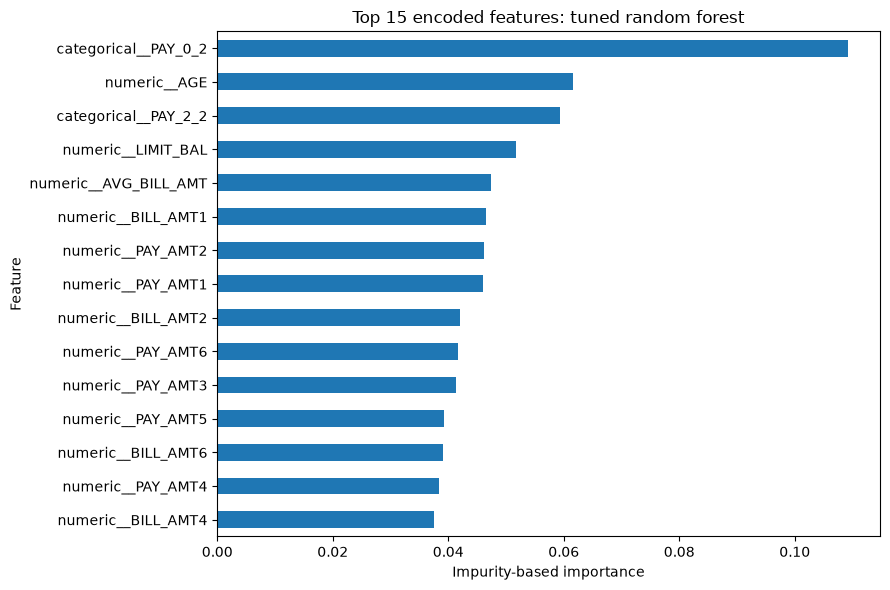

In [41]:
top_features = forest_importances.head(15).sort_values("Importance")
top_features.plot.barh(x="Feature", y="Importance", legend=False, figsize=(9, 6))
plt.xlabel("Impurity-based importance")
plt.title("Top 15 encoded features: tuned random forest")
plt.tight_layout()
plt.show()

In [42]:
encoder = fitted_preprocessor.named_transformers_["categorical"].named_steps["onehotencoder"]
original_names = list(numeric_features)
for feature, categories in zip(categorical_features, encoder.categories_):
    original_names.extend([feature] * len(categories))

grouped_importances = (
    pd.DataFrame({
        "Feature": original_names,
        "Importance": best_forest.feature_importances_
    })
    .groupby("Feature")["Importance"].sum()
    .sort_values(ascending=False)
)
grouped_importances.head(10)

Feature
PAY_0           0.133664
PAY_2           0.070385
AGE             0.061603
LIMIT_BAL       0.051757
AVG_BILL_AMT    0.047342
BILL_AMT1       0.046476
PAY_AMT2        0.046221
PAY_AMT1        0.046033
BILL_AMT2       0.041957
PAY_AMT6        0.041652
Name: Importance, dtype: float64

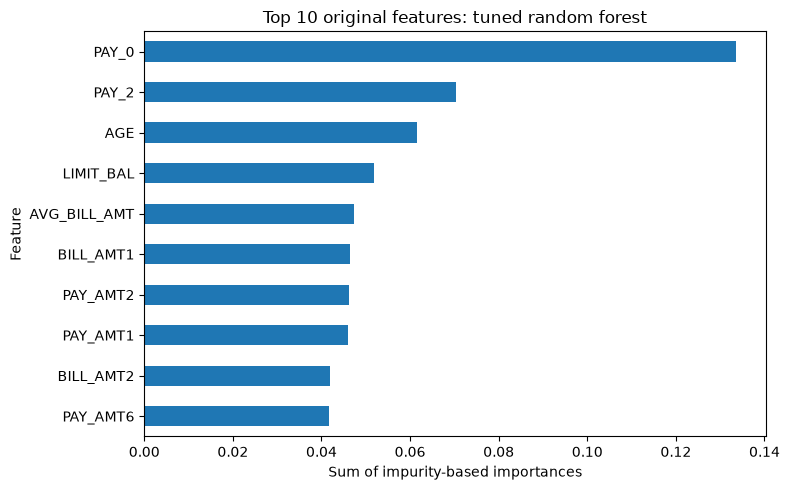

In [43]:
grouped_importances.head(10).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel("Sum of impurity-based importances")
plt.title("Top 10 original features: tuned random forest")
plt.tight_layout()
plt.show()

The five highest-ranked original features are PAY_0 (0.134), PAY_2 (0.070), AGE (0.062), LIMIT_BAL (0.052), AVG_BILL_AMT (0.047). These are the inputs most used by this fitted forest to reduce impurity. Repayment-status features describe past payment behavior, while credit limits, bill amounts, and payment amounts describe different aspects of a client's financial history. The ranking helps assess our initial hypothesis about the importance of repayment behavior.

PAY_0 and PAY_2 have the highest grouped importances, supporting our initial hypothesis that repayment history is useful. The PAY_0 category 2 indicator is the strongest individual encoded feature. AGE, LIMIT_BAL, and AVG_BILL_AMT also contribute substantially. This ranking alone does not establish which direction these features affect default predictions.

Importances do not show whether a higher feature value increases or decreases the predicted default probability. They describe the fitted model, not causal effects or a unique list of relevant features. Impurity-based importance can favor continuous variables or variables with many possible split points. Summing one-hot importances helps compare original variables, but does not remove this bias. Correlated monthly bills and payment histories can share importance; AVG_BILL_AMT also overlaps with its six source bill columns. Given the forest's training-versus-CV gap, these training-derived rankings should be interpreted cautiously and do not establish generalization or fairness.

In [44]:
...

Ellipsis

In [45]:
...

Ellipsis

In [46]:
...

Ellipsis

In [47]:
...

Ellipsis

In [48]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 12. Results on the test set <a name="12"></a>
<hr>

rubric={points:10}

**Your tasks:**

1. Try your best performing model on the test data and report test scores. 
2. Do the test scores agree with the validation scores from before? To what extent do you trust your results? Do you think you've had issues with optimization bias? 
3. Take one or two test predictions and explain these individual predictions (e.g., with SHAP force plots).  

<div class="alert alert-warning">
    
Solution_12
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

We evaluate the tuned random forest selected in Question 10 using the held-out test set, with default (1) as the positive class. We report accuracy, precision, recall, F1, and a confusion matrix. We keep the selected hyperparameters and default classification threshold fixed. For local interpretation, we use SHAP waterfall plots.

In [49]:
final_model = forest_search.best_estimator_
X_test = test_df.drop(columns=["default.payment.next.month"])
y_test = test_df["default.payment.next.month"]
test_predictions = final_model.predict(X_test)

test_results = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision (default=1)": precision_score(y_test, test_predictions, zero_division=0),
    "Recall (default=1)": recall_score(y_test, test_predictions),
    "F1 (default=1)": f1_score(y_test, test_predictions)
})
print(test_results.round(4))
print("Selected model mean CV F1:", forest_search.best_score_)
print(classification_report(
    y_test, test_predictions, target_names=["No default", "Default"],
    digits=4, zero_division=0
))

Accuracy                 0.8177
Precision (default=1)    0.6322
Recall (default=1)       0.3768
F1 (default=1)           0.4722
dtype: float64
Selected model mean CV F1: 0.4802319082085417
              precision    recall  f1-score   support

  No default     0.8451    0.9394    0.8898      7052
     Default     0.6322    0.3768    0.4722      1948

    accuracy                         0.8177      9000
   macro avg     0.7387    0.6581    0.6810      9000
weighted avg     0.7990    0.8177    0.7994      9000



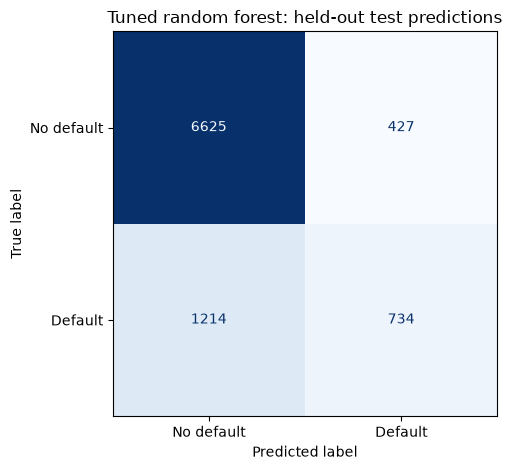

In [50]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=["No default", "Default"],
    cmap="Blues", colorbar=False
)
plt.title("Tuned random forest: held-out test predictions")
plt.tight_layout()
plt.show()

In [51]:
explanation_rows = X_test.iloc[:2]
explanation_preprocessor = final_model.named_steps["columntransformer"]
explanation_forest = final_model.named_steps["randomforestclassifier"]
encoded_rows = explanation_preprocessor.transform(explanation_rows)
if hasattr(encoded_rows, "toarray"):
    encoded_rows = encoded_rows.toarray()

explainer = shap.TreeExplainer(
    explanation_forest,
    feature_names=explanation_preprocessor.get_feature_names_out()
)
all_class_explanations = explainer(encoded_rows)
default_class_index = list(explanation_forest.classes_).index(1)
default_explanations = all_class_explanations[:, :, default_class_index]
example_probabilities = final_model.predict_proba(explanation_rows)[:, default_class_index]

assert np.allclose(
    default_explanations.base_values + default_explanations.values.sum(axis=1),
    example_probabilities
)
example_results = pd.DataFrame({
    "Actual default": y_test.iloc[:2].to_numpy(),
    "Predicted default": test_predictions[:2],
    "Predicted default probability": example_probabilities,
    "SHAP reference probability": default_explanations.base_values
}, index=explanation_rows.index)
example_results

,Actual default,Predicted default,Predicted default probability,SHAP reference probability
25665,0,0,0.216043,0.223506
16464,0,0,0.066956,0.223506


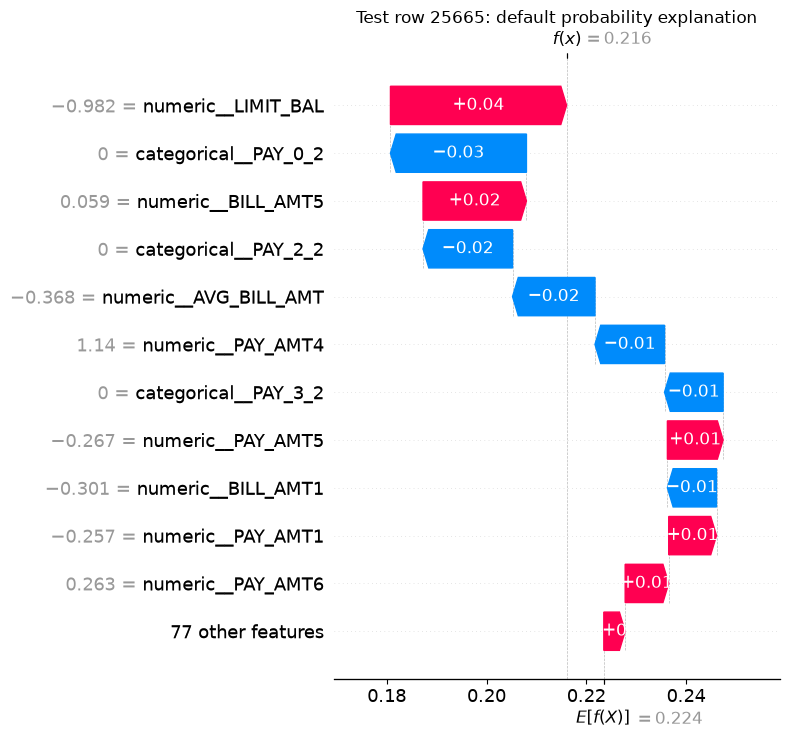

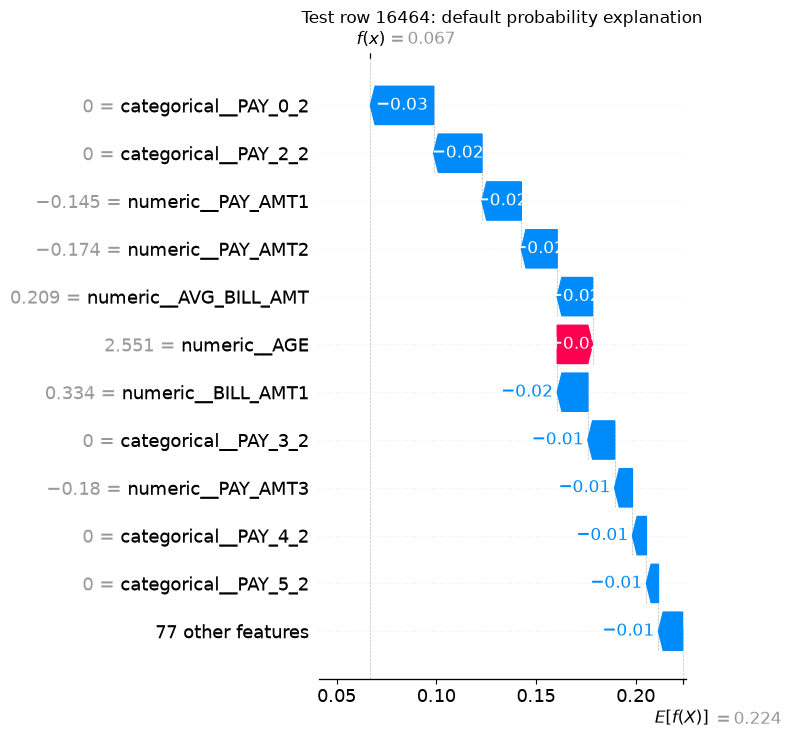

In [52]:
for i in range(2):
    shap.plots.waterfall(default_explanations[i], max_display=12, show=False)
    plt.title(f"Test row {explanation_rows.index[i]}: default probability explanation")
    plt.tight_layout()
    plt.show()

The test F1-score is 0.4722, compared with mean CV F1 of 0.4802 (fold standard deviation 0.0106). The absolute difference is 0.0081. 
The test F1 is reasonably close to the CV result, so this evaluation does not show a large performance collapse. However, recall is only 0.3768: the model identifies about 37.7% of actual defaults and misses about 62.3%. Precision is 0.6322, meaning about 63.2% of its default predictions are correct. Accuracy of 0.8177 should therefore not be interpreted as evidence that the model catches most defaults. 
These are results from different samples; fold standard deviation is not a confidence interval for the test score. We have some reason to trust the workflow because preprocessing and model selection used training-set CV and the test set was reserved for this final evaluation. However, selecting the highest CV score across models, feature choices, and hyperparameters can cause optimization bias: the winning CV score may benefit from chance. A single held-out test result does not eliminate uncertainty, and the large training-versus-CV gap indicates overfitting. These results describe a random split of this dataset and may not reflect performance on future clients or different populations. We do not use these test results to retune the model.

For test row 25665, the actual label is 0 and the predicted label is 0. The predicted default probability is 0.216, compared with SHAP reference 0.224. The largest absolute contributions are numeric__LIMIT_BAL (+0.035), categorical__PAY_0_2 (-0.027), numeric__BILL_AMT5 (+0.021).

For test row 16464, the actual label is 0 and the predicted label is 0. The predicted default probability is 0.067, compared with SHAP reference 0.224. The largest absolute contributions are categorical__PAY_0_2 (-0.032), categorical__PAY_2_2 (-0.024), numeric__PAY_AMT1 (-0.020).


The SHAP reference uses TreeExplainer's tree-path-dependent background based on training observations. For this random forest, the verified output scale is default probability: reference probability plus feature contributions equals the predicted default probability. Positive contributions increase the prediction relative to the reference; negative contributions decrease it. Numeric values in the plots are standardized, and categorical values are one-hot indicators. Contributions describe these two model predictions, not causal effects; correlated inputs can affect how credit is allocated. These two rows illustrate local behavior and are not a representative performance assessment.

In [53]:
...

Ellipsis

In [54]:
...

Ellipsis

In [55]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 13. Summary of results <a name="13"></a>
<hr>
rubric={points:12}

Imagine that you want to present the summary of these results to your boss and co-workers. 

**Your tasks:**

1. Create a table summarizing important results. 
2. Write concluding remarks.
3. Discuss other ideas that you did not try but could potentially improve the performance/interpretability . 
3. Report your final test score along with the metric you used at the top of this notebook in the [Submission instructions section](#si).

<div class="alert alert-warning">
    
Solution_13
    
</div>

_Points:_ 12

_Type your answer here, replacing this text._

In [56]:
results_summary = pd.DataFrame({
    "Model": [
        "DummyClassifier (majority class)",
        "Logistic regression (C=10)",
        "Logistic regression with RFE (44 features)",
        "Tuned kNN",
        "Tuned decision tree",
        "Tuned random forest (selected)"
    ],
    "Mean CV F1": [0.0000, 0.4687, 0.4717, 0.4253, 0.4665, 0.4802],
    "CV F1 std": [0.0000, 0.0100, 0.0109, 0.0092, 0.0094, 0.0106],
    "Final test F1": [None, None, None, None, None, 0.4722]
}).set_index("Model")

results_summary.round(4)

,Mean CV F1,CV F1 std,Final test F1
Model,,,
DummyClassifier (majority class),0.0000,0.0000,NaN
Logistic regression (C=10),0.4687,0.0100,NaN
Logistic regression with RFE (44 features),0.4717,0.0109,NaN
Tuned kNN,0.4253,0.0092,NaN
Tuned decision tree,0.4665,0.0094,NaN
Tuned random forest (selected),0.4802,0.0106,0.4722


The tuned random forest achieved the highest mean CV F1 and was selected for final evaluation. Its test F1 was 0.4722, with precision 0.6322, recall 0.3768, and accuracy 0.8177. The test F1 was close to the CV result, but the model detected only about 37.7% of actual defaults. It improves on the majority-class baseline, which never detects defaults, but its low recall limits its usefulness when missed defaults are costly. F1 balances precision and recall without specifying the actual costs of these errors, so the preferred operating point would depend on the intended use.

Tuning improved all three non-linear models. RFE slightly improved logistic regression, but did not exceed the tuned forest. Logistic regression remains a useful alternative because its validation performance was close and it is simpler to inspect. The random forest had a large gap between training F1 (0.8697) and CV F1 (0.4802), indicating substantial overfitting, and it was much more expensive to fit. Its small CV advantage should not be interpreted as conclusive evidence that it will always outperform the other models. Searching across models and settings can introduce optimization bias, and this single random split does not establish performance on future populations.

The feature-importance analysis ranked PAY_0 and PAY_2 highest, supporting our initial hypothesis that repayment history would be informative. SHAP illustrated how individual features contributed to two predictions. These explanations describe the fitted model, not causal effects, and correlated features and impurity-importance bias limit how confidently we can interpret the rankings.

Ideas we did not try include tuning class weights or choosing a decision threshold using training-set validation predictions to improve recall, while monitoring the resulting precision trade-off. We could also try a boosting model such as LightGBM, and investigate credit-utilization ratios or summaries of payment delays as additional features. For interpretation, permutation importance on held-out development folds could complement impurity-based rankings, and a smaller model could be considered if its predictive performance is comparable. These are proposals for future work, not demonstrated improvements. Any further tuning should use development data; the test results reported here should not guide new choices. A fresh evaluation set would be needed for an independent assessment after further development.

<!-- END QUESTION -->

<br><br>

<br><br>

<!-- BEGIN QUESTION -->

## (Challenging) 14. Your takeaway <a name="15"></a>
<hr>
rubric={points:2}

**Your tasks:**

What is your biggest takeaway from the supervised machine learning material we have learned so far? Please write thoughtful answers.  

<div class="alert alert-warning">
    
Solution_14
    
</div>

_Points:_ 2

My biggest takeaway from the supervised machine learning material so far is understanding how different models learn patterns from data and how their performance can be improved through techniques such as cross-validation and hyperparameter tuning. I found the content very interesting so I decided to work on a personal project that involved training and tuning classification models.

<!-- END QUESTION -->

<br><br>

Before submitting your assignment, please make sure you have followed all the instructions in the Instructions section at the top.

Here is a quick checklist before submitting:

- [ ] Restart the kernel and run all cells.
- [ ] `hw5.ipynb` runs without errors and contains all outputs.
- [ ] Save `hw5.ipynb` in JupyterLab.
- [ ] Return to the PrairieLearn question page and click **Save only** to check the rendered notebook preview.
- [ ] When the preview looks correct, click **Save & Grade**.
- [ ] If you are working in a group, confirm your PrairieLearn group membership is correct.
- [ ] Review the CPSC 330 homework instructions on the course website for details on the grading process.


This was a tricky one but you did it! Have a great weekend! 

![](img/eva-well-done.png)